In [1]:
import pandas as pd
import numpy as np
import ast

meta = pd.read_csv("/yunity/tkerby2/Local_CorEx/Local_CorEx_Experiments/benchmark_results/mnist_factor_benchmark/factor_metadata.csv")
abl = pd.read_csv("/yunity/tkerby2/Local_CorEx/Local_CorEx_Experiments/benchmark_results/mnist_factor_benchmark/factor_ablations.csv")

print(meta.shape)
print(abl.shape)

meta.head()
abl.head()

(600, 50)
(5400, 20)


,factor_id,support_level,support_size,support_density,cumulative_mi,global_tv,local_tv,global_entropy,local_entropy,global_dom_fraction,local_dom_fraction,class_associated_global,class_associated_local,global_delta_probs,local_delta_probs,global_class_accuracy_change,local_class_accuracy_change,cluster_id,layer,support_nodes
0,0,0.1,2,0.004,0.100151,0.000377,0.000516,0.922184,0.574704,0.219801,0.431372,False,False,"[-4.559755325317383e-05, -0.000106804072856903...","[-6.289413434501512e-14, -0.000445485115051269...","[-0.0010204081632653184, -0.000881057268722451...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,1,"[173, 473]"
1,0,0.2,10,0.020,0.204515,0.001347,0.005126,0.802170,0.611755,0.256824,0.451879,False,False,"[7.315725088119507e-05, -0.0004392638802528381...","[7.568388693535155e-10, -0.004632294178009033,...","[0.0, -0.0035242290748898064, 0.0, -0.00297029...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.125, 0.0...",0,1,"[173, 473, 308, 267, 87, 401, 33, 171, 439, 449]"
2,0,0.3,21,0.042,0.306168,0.003038,0.006460,0.807444,0.585503,0.280503,0.499974,False,False,"[5.4955482482910156e-05, -0.000633269548416137...","[1.8815018432150055e-09, -0.006459534168243408...","[-0.0010204081632653184, -0.005286343612334821...","[0.0, -0.0024449877750611915, 0.0, 0.0, 0.0, 0...",0,1,"[173, 473, 308, 267, 87, 401, 33, 171, 439, 44..."
3,0,0.4,35,0.070,0.406271,0.003831,0.013508,0.806572,0.559058,0.245575,0.499995,False,False,"[-6.743520498275757e-05, -0.001046769320964813...","[4.140376486105879e-09, -0.013507604598999023,...","[-0.0020408163265306367, -0.005286343612334821...","[0.0, -0.007334963325183463, 0.0, 0.0, 0.0, 0....",0,1,"[173, 473, 308, 267, 87, 401, 33, 171, 439, 44..."
4,0,0.5,51,0.102,0.502166,0.004122,0.016911,0.777639,0.579859,0.275624,0.491390,False,False,"[-2.682209014892578e-07, -0.001407623291015625...","[1.0482975376646664e-08, -0.016619980335235596...","[-0.0020408163265306367, -0.007048458149779724...","[0.0, -0.009779951100244544, 0.0, 0.0, 0.0, 0....",0,1,"[173, 473, 308, 267, 87, 401, 33, 171, 439, 44..."


In [2]:
meta.groupby("layer").size()

layer
1    200
2    200
3    200
dtype: int64

In [3]:
meta.groupby("layer")[
    [
        "support_size_60",
        # "support_size_70",
        # "support_size_80",
        # "support_size_90",
    ]
].describe()

support_size_60                                                 
                count    mean       std   min   25%   50%    75%   max
layer                                                                 
1               200.0  56.970  9.886751  31.0  50.0  56.0  62.25  92.0
2               200.0  39.865  8.854308  22.0  34.0  39.0  45.00  77.0
3               200.0  30.960  8.485779  13.0  25.0  30.0  37.00  59.0

In [4]:
meta.groupby("layer")[
    [
        "support_density_10",
        "support_density_20",
        "support_density_30",
        "support_density_40",
        "support_density_50",
        "support_density_60",
        "support_density_70",
        "support_density_80",
        "support_density_90",
    ]
].median()

,support_density_10,support_density_20,support_density_30,support_density_40,support_density_50,support_density_60,support_density_70,support_density_80,support_density_90
layer,,,,,,,,,
1,0.006000,0.014000,0.028000,0.048000,0.076,0.1120,0.1640,0.242000,0.370000
2,0.005000,0.012500,0.022500,0.040000,0.065,0.0975,0.1475,0.222500,0.347500
3,0.003333,0.006667,0.016667,0.036667,0.060,0.1000,0.1500,0.226667,0.356667


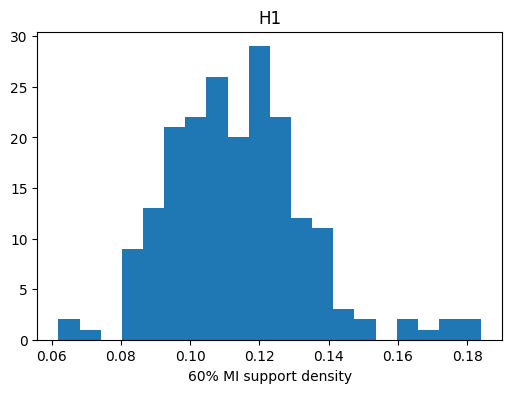

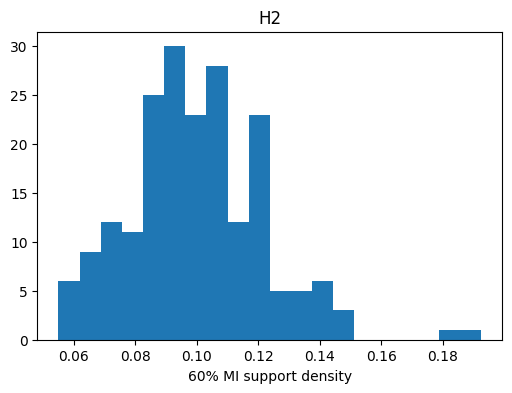

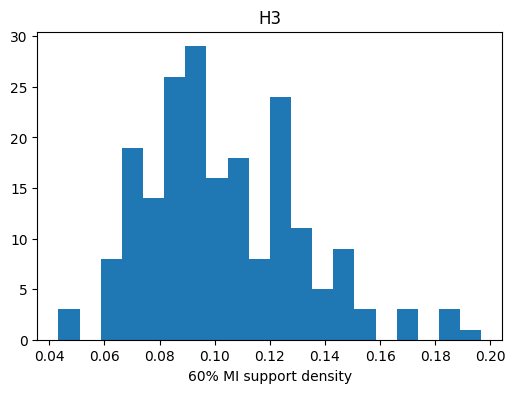

In [5]:
import matplotlib.pyplot as plt

for layer in sorted(meta.layer.unique()):
    plt.figure(figsize=(6,4))
    subset = meta.query("layer == @layer")

    plt.hist(
        subset["support_density_60"],
        bins=20,
    )

    plt.title(f"H{layer}")
    plt.xlabel("60% MI support density")
    plt.show()

In [6]:
abl[
    [
        "global_tv",
        "local_tv",
    ]
].describe()

,global_tv,local_tv
count,5400.000000,5400.000000
mean,0.008259,0.019917
std,0.016837,0.054446
min,0.000057,0.000009
25%,0.000917,0.001174
50%,0.002584,0.003988
75%,0.007209,0.013890
max,0.209712,0.874129


In [7]:
abl.groupby("layer")[
    [
        "local_tv",
        "global_tv",
    ]
].mean()

,local_tv,global_tv
layer,,
1,0.026885,0.013368
2,0.018988,0.006153
3,0.013879,0.005255


array([[<Axes: title={'center': 'local_entropy'}>,
        <Axes: title={'center': 'global_entropy'}>]], dtype=object)

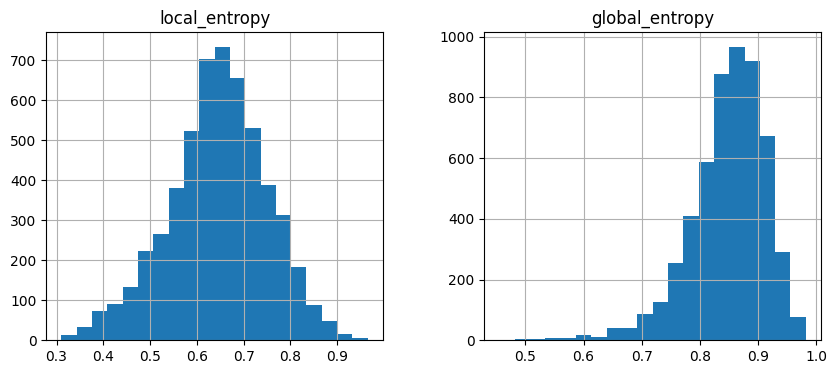

In [8]:
abl[
    [
        "local_entropy",
        "global_entropy",
    ]
].hist(
        figsize=(10,4),
        bins=20,
)

In [9]:
merged = abl.merge(
    meta[
        [
            "cluster_id",
            "layer",
            "factor_id",
            "tc_explained",
        ]
    ],
    on=[
        "cluster_id",
        "layer",
        "factor_id",
    ],
)

merged[
    [
        "tc_explained",
        "local_tv",
    ]
].corr()

,tc_explained,local_tv
tc_explained,1.000000,0.123615
local_tv,0.123615,1.000000


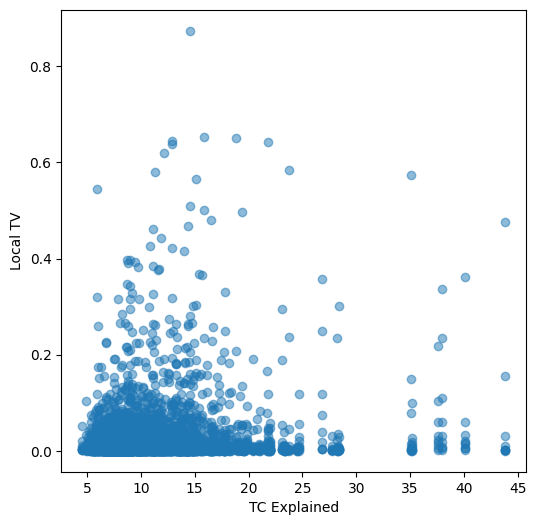

In [10]:
plt.figure(figsize=(6,6))

plt.scatter(
    merged["tc_explained"],
    merged["local_tv"],
    alpha=.5,
)

plt.xlabel("TC Explained")
plt.ylabel("Local TV")
plt.show()

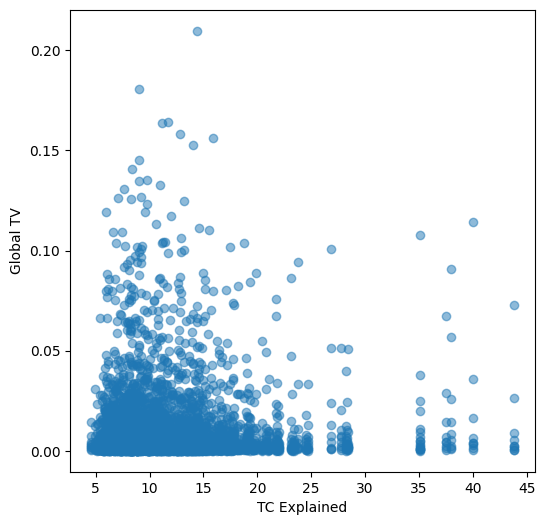

In [11]:
plt.figure(figsize=(6,6))

plt.scatter(
    merged["tc_explained"],
    merged["global_tv"],
    alpha=.5,
)

plt.xlabel("TC Explained")
plt.ylabel("Global TV")
plt.show()

In [12]:
merged.groupby("layer")[
    [
        "local_tv",
        "local_entropy",
        "global_tv",
        "global_entropy",
    ]
].mean()

,local_tv,local_entropy,global_tv,global_entropy
layer,,,,
1,0.026885,0.651772,0.013368,0.843346
2,0.018988,0.631412,0.006153,0.842750
3,0.013879,0.653208,0.005255,0.857682


In [13]:
merged.sort_values(
    "local_tv",
    ascending=False,
).head(20)

,factor_id,support_level,support_size,support_density,cumulative_mi,global_tv,local_tv,global_entropy,local_entropy,global_dom_fraction,...,class_associated_global,class_associated_local,global_delta_probs,local_delta_probs,global_class_accuracy_change,local_class_accuracy_change,cluster_id,layer,support_nodes,tc_explained
62,6,0.9,213,0.426000,0.901177,0.111157,0.874129,0.869853,0.402804,0.216081,...,False,True,"[0.0018484517931938171, -0.04803784191608429, ...","[0.0005611072992905974, -0.8629187941551208, 0...","[-0.01224489795918371, -0.4079295154185022, 0....","[0.0, -0.9193154034229829, 0.0, 0.0, -0.333333...",0,1,"[0, 198, 461, 353, 233, 260, 193, 154, 101, 9,...",14.570859
3518,0,0.9,187,0.374000,0.901038,0.156101,0.653802,0.607959,0.322090,0.458533,...,False,True,"[0.0006135031580924988, -0.04639802128076553, ...","[-0.00010275442036800086, -1.1168545825057663e...","[-0.01224489795918371, -0.36211453744493394, -...","[0.0, 0.0, 0.0, 0.0, -0.9776119402985075, 0.0,...",13,1,"[222, 286, 120, 5, 211, 239, 487, 191, 50, 441...",15.904838
1106,2,0.9,178,0.356000,0.900274,0.103994,0.651525,0.860736,0.488420,0.240189,...,False,False,"[-0.0061416104435920715, -0.037018731236457825...","[-0.0007516071200370789, -0.6307336091995239, ...","[-0.04489795918367345, -0.3198237885462555, -0...","[1.0, -0.6927710843373494, -0.2000000000000000...",4,1,"[273, 72, 311, 406, 258, 284, 12, 156, 443, 20...",18.801516
4823,5,0.9,126,0.420000,0.901653,0.078871,0.644267,0.547376,0.376009,0.435370,...,False,True,"[-0.0008865967392921448, -0.00218036025762558,...","[0.0014614616520702839, -0.0005117491236887872...","[-0.0071428571428571175, -0.007929515418502175...","[0.0, 0.0, 0.0, -0.017241379310344862, 0.0, -0...",17,3,"[99, 134, 160, 242, 164, 245, 10, 97, 42, 15, ...",12.875570
197,1,0.9,125,0.416667,0.900121,0.067178,0.643077,0.677373,0.338767,0.381031,...,False,True,"[-0.000304296612739563, -0.05119408667087555, ...","[4.0321243432117626e-05, -0.6430773735046387, ...","[-0.004081632653061162, -0.4308370044052863, 0...","[0.0, -0.8581907090464548, 0.0, 0.0, 0.0, 0.0,...",0,3,"[252, 56, 143, 145, 265, 169, 254, 131, 206, 2...",21.767624
1160,8,0.9,188,0.376000,0.900640,0.069397,0.638143,0.811077,0.591383,0.279616,...,False,False,"[-0.0002733394503593445, -0.0328369140625, -0....","[0.007793744094669819, -0.6123138070106506, 0....","[-0.010204081632653073, -0.22466960352422904, ...","[1.0, -0.608433734939759, 0.0, 0.0, -0.5, 0.0,...",4,1,"[308, 33, 143, 173, 284, 437, 223, 197, 457, 4...",12.861704
3860,8,0.9,176,0.352000,0.900979,0.071294,0.620388,0.701325,0.529782,0.352166,...,False,False,"[-0.00015262514352798462, -0.05021485686302185...","[0.000983131816610694, -0.6175459027290344, 0....","[-0.005102040816326481, -0.36916299559471366, ...","[0.0, -0.6157894736842106, -1.0, 0.0, -0.25, 0...",14,1,"[223, 498, 184, 415, 198, 283, 377, 263, 354, ...",12.148720
3707,1,0.9,124,0.413333,0.900082,0.094418,0.583451,0.541658,0.336190,0.427802,...,False,True,"[-0.002752728760242462, -0.003408685326576233,...","[-0.00019966506806667894, 8.852312930685002e-0...","[-0.01224489795918371, -0.014096916299559448, ...","[0.0, 0.0, 0.0, 0.0, -0.9888059701492538, 0.0,...",13,3,"[238, 13, 4, 53, 247, 159, 37, 212, 122, 137, ...",23.786745
3869,9,0.9,166,0.332000,0.900413,0.104406,0.580544,0.795675,0.384562,0.365322,...,False,True,"[-0.003771364688873291, -0.05049799382686615, ...","[0.0001504559040768072, -0.5747268199920654, -...","[-0.020408163265306145, -0.4511013215859031, -...","[0.0, -0.5973684210526315, -1.0, 0.0, -0.5, 0....",14,1,"[448, 268, 270, 489, 115, 452, 58, 465, 359, 1...",11.277808
3788,0,0.9,179,0.358000,0.900293,0.107730,0.574324,0.779734,0.536576,0.240109,...,False,False,"[-0.0016783177852630615, -0.051733870059251785...","[0.0003066234348807484, -0.5666259527206421, 0...","[-0.014285714285714235, -0.4096916299559471, -...","[0.0, -0.5263157894736843, 0.0, 0.0, -0.75, 0....",14,1,"[468, 370, 92, 368, 6, 458, 230, 297, 249, 451...",35.06702

In [15]:
abl.groupby("layer")[
    "class_associated_local"
].mean()

layer
1    0.025
2    0.050
3    0.025
Name: class_associated_local, dtype: float64

In [17]:
row = merged.sort_values(
    "local_tv",
    ascending=False,
).iloc[0]

row

import ast

delta = np.array(
    ast.literal_eval(
        row["local_delta_probs"]
    )
)

pd.Series(delta).sort_values()

4   -0.072913
5   -0.001436
1   -0.000135
2   -0.000097
0    0.000028
3    0.000053
6    0.000244
8    0.000578
7    0.002141
9    0.071537
dtype: float64

In [22]:
merged.groupby("layer").agg(
    mean_tc=("tc_explained","mean"),
    mean_tv=("local_tv","mean"),
    mean_entropy=("local_entropy","mean"),
    # mean_density=("support_density_60","mean"),
)

,mean_tc,mean_tv,mean_entropy
layer,,,
1,16.131722,0.016707,0.644554
2,16.073707,0.017796,0.628495
3,18.118538,0.008962,0.640100


In [23]:
merged.sort_values(
    "local_tv",
    ascending=False,
)[
    [
        "cluster_id",
        "layer",
        "factor_id",
        "tc_explained",
        # "support_density_60",
        "local_tv",
        "local_entropy",
    ]
].head(30)

,cluster_id,layer,factor_id,tc_explained,local_tv,local_entropy
62,10,2,0,26.812349,0.074580,0.371506
64,10,3,0,37.945377,0.059862,0.366494
80,13,2,0,16.182411,0.058935,0.356489
85,14,1,1,19.346481,0.053128,0.440009
14,2,2,0,12.758912,0.048892,0.394506
103,17,1,1,12.856337,0.047567,0.632404
104,17,2,0,13.279552,0.043627,0.621773
90,15,1,0,9.763046,0.042822,0.659321
105,17,2,1,11.046177,0.042659,0.608285
7,1,1,1,11.832539,0.041981,0.599379
